# Generate label predictions on validation images
Note: all models compared need to operate on the same dataset.

In [17]:
import os
import sys
import pandas as pd
import matplotlib.pylab as plt
import torch

PROJECT_ROOT = os.path.abspath(".")
if not os.path.exists(os.path.join(PROJECT_ROOT, "config", "binary_model_v1.yml")):
    PROJECT_ROOT = os.path.abspath("MONAI-test")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.config import load_yaml_config

CONFIG_PATHS = [
    # os.path.join(PROJECT_ROOT, "config", "binary_model_v1.yml"),
    # os.path.join(PROJECT_ROOT, "config", "binary_model_v3.yml"),
   os.path.join(PROJECT_ROOT, "config", "binary_model_v4_synaptic_hcs.yml"),

]

# Select either "cytoSam" or "cyto2".
# Cellpose 4 supports Cellpose-SAM as "cpsam_v2"; cyto2 requires an older Cellpose API.
CELLPOSE_MODEL_NAME = "cytoSam"
CELLPOSE_DIAMETER = None
CELLPOSE_CHANNELS = [0, 0]
CELLPOSE_FLOW_THRESHOLD = 0.0
CELLPOSE_CELLPROB_THRESHOLD = 0.0
CELLPOSE_MIN_SIZE = 800

model_runs = []
for config_path in CONFIG_PATHS:
    model_runs.append({
        "name": os.path.splitext(os.path.basename(config_path))[0],
        "config_path": config_path,
        "config": load_yaml_config(config_path),
    })

config = model_runs[0]["config"]
data_config = config["data"]
augmentation_config = config["augmentation"]
training_config = config["training"]
validation_config = config["validation"]


def resolve_project_path(path):
    if os.path.isabs(path):
        return path
    return os.path.join(PROJECT_ROOT, path)


patch_size = tuple(data_config["patch_size"])
data_dir = resolve_project_path(data_config["data_dir"])
split_file = resolve_project_path(data_config["split_file"])


In [18]:
from src import data, transforms,inference

excel_folder = resolve_project_path(data_config["excel_folder"])
alldata = data.load_all_excels(folder=excel_folder, drive=data_config["drive"],
                    exclusions=None if data_config.get("exclusions", None) == "None" else data_config.get("exclusions", None),
                    inclusions = None if data_config.get("inclusions", None) == "None" else data_config.get("inclusions", None))
dfdata = data.generate_dataset(
    alldata,
    copy_type=data_config["copy_type"],
    overwrite=data_config["overwrite"],
    local_data_folder=data_dir,
    require_annotations=data_config.get("require_annotations", True)
)


 16%|█▌        | 47/297 [00:00<00:01, 164.93it/s]

Avg file does not exist: /Volumes/data/Users/Francesca/Data/2023/2023_03_31_NeuroD-GCaMP6f_P4_in vivo/1/processedMovies/Avg.tif
Avg file does not exist: /Volumes/data/Users/Francesca/Data/2023/2023_04_04_NeuroD-GCaMP6f_P8_in vivo/1/processedMovies/Avg.tif
Avg file does not exist: /Volumes/data/Users/Francesca/Data/2023/2023_06_09_NeuroD-GCaMP6f_P8_in vivo/1/processedMovies/Avg.tif


 49%|████▉     | 146/297 [00:00<00:00, 199.90it/s]

Avg file does not exist: /Volumes/data/Users/Francesca/Data/2025/2025_04_28_NeuroD-GCaMP6f_P7_in vivo_injectable anaesthetic/3/processedMovies/Avg.tif
Avg file does not exist: /Volumes/data/Users/Francesca/Data/2025/2025_04_28_NeuroD-GCaMP6f_P7_in vivo_injectable anaesthetic/3_001/processedMovies/Avg.tif
Avg file does not exist: /Volumes/data/Users/Francesca/Data/2025/2025_04_28_NeuroD-GCaMP6f_P7_in vivo_injectable anaesthetic/3_002/processedMovies/Avg.tif
Masks file does not exist: /Volumes/data/Users/Francesca/Data/2023/2023_03_16_6N-Rep_iGluSnFR-syn-AAV_P9_in vivo/1/processedMovies/Masks.tif
Avg file does not exist: /Volumes/data/Users/Francesca/Data/2023/2023_03_16_6N-Rep_iGluSnFR-syn-AAV_P9_in vivo/2/processedMovies/Avg.tif
Avg file does not exist: /Volumes/data/Users/Francesca/Data/2023/2023_03_16_6N-Rep_iGluSnFR-syn-AAV_P9_in vivo/3/processedMovies/Avg.tif
Avg file does not exist: /Volumes/data/Users/Francesca/Data/2023/2023_03_16_6N-Rep_iGluSnFR-syn-AAV_P9_in vivo/4/processedMo

 68%|██████▊   | 203/297 [00:01<00:00, 225.39it/s]

Avg file does not exist: /Volumes/data/Users/Francesca/Data/2023/2023_06_20_SNAP25-GCaMP6s_P8_in vivo/4_001/processedMovies/Avg.tif
Avg file does not exist: /Volumes/data/Users/Francesca/Data/2023/2023_06_29_SNAP25-GCaMP6s_P4_in vivo/3/processedMovies/Avg.tif
Avg file does not exist: E:/Users/Federico/Data/2024/InVivoProject/20240910-SNAP25-RT-GCampExplant/1-RT/processedMovies/Avg.tif
Avg file does not exist: E:/Users/Federico/Data/2024/InVivoProject/20240910-SNAP25-RT-GCampExplant/2-RT/processedMovies/Avg.tif
Avg file does not exist: E:/Users/Federico/Data/2024/InVivoProject/20240911-SNAP25-RT-GCampExplant/1-P9-RT/processedMovies/Avg.tif
Avg file does not exist: E:/Users/Federico/Data/2024/InVivoProject/20240911-SNAP25-RT-GCampExplant/2-P9-RT/processedMovies/Avg.tif
Avg file does not exist: E:/Users/Federico/Data/2024/InVivoProject/20240911-SNAP25-RT-GCampExplant/3-P9-RT_001/processedMovies/Avg.tif
Avg file does not exist: E:/Users/Federico/Data/2024/InVivoProject/20240911-SNAP25-RT-G

100%|██████████| 297/297 [00:01<00:00, 205.23it/s]


## 1. Load the train/test split from the json file

In [19]:
train_data, val_data = data.train_test_split(
    dfdata,
    column=data_config["column"],
    test_size=data_config["test_size"],
    random_state=data_config["random_state"],
    split_json_path=split_file,
    save_split_json=data_config["save_split_json"],
    data_dir=data_dir,
    require_annotations=data_config.get("require_annotations", True)
)


## 2. Load the transformations on train and val (val does not have data augmentations)

In [20]:
train_transforms, val_transforms = transforms.get_transforms_binary_classification(
    num_samples=data_config["num_samples"],
    spatial_size=patch_size,
    pos=data_config["pos"],
    neg=data_config["neg"],
    filter_by_annotation=data_config["require_annotations"],
    annotation_indices=data_config["annotation_indices"],
    flip_vertical=augmentation_config["flip_vertical"],
    flip_vertical_prob=augmentation_config["flip_vertical_prob"],
    flip_horizontal=augmentation_config["flip_horizontal"],
    flip_horizontal_prob=augmentation_config["flip_horizontal_prob"],
    rotate90=augmentation_config["rotate90"],
    rotate90_prob=augmentation_config["rotate90_prob"],
    rotate90_max_k=augmentation_config["rotate90_max_k"],
    intensity_scale=augmentation_config["intensity_scale"],
    intensity_scale_prob=augmentation_config["intensity_scale_prob"],
    intensity_scale_factors=augmentation_config["intensity_scale_factors"],
    intensity_shift=augmentation_config["intensity_shift"],
    intensity_shift_prob=augmentation_config["intensity_shift_prob"],
    intensity_shift_offsets=augmentation_config["intensity_shift_offsets"],
)


## 3. Create datasets and dataloaders

In [21]:
# Create dataset and dataloader
train_ds, train_loader, val_ds, val_loader = data.create_datasets_and_loaders(
    train_data,
    val_data,
    train_transforms,
    val_transforms,
    batch_size=training_config["batch_size"],
    val_batch_size=training_config["val_batch_size"],
    num_workers=training_config["num_workers"],
    shuffle_train=training_config["shuffle_train"],
    shuffle_val=training_config["shuffle_val"],
)

# define torch device
configured_device = training_config["device"]
if configured_device == "auto":
    if torch.cuda.is_available():
        device = torch.device("cuda")
    elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        device = torch.device("mps")
    else:
        device = torch.device("cpu")
else:
    device = torch.device(configured_device)
print("Using device:", device)


Using device: mps


## 4. Define the model and various training metrics and postprocessing

In [22]:
# Load UNet models and Cellpose
from src.model import build_binary_model
import numpy as np
for run in model_runs:
    model_config = run["config"]["model"]
    model = build_binary_model(
        architecture=model_config["architecture"],
        spatial_dims=model_config["spatial_dims"],
        in_channels=model_config["in_channels"],
        out_channels=model_config["out_channels"],
        channels=model_config["channels"],
        strides=model_config["strides"],
        num_res_units=model_config["num_res_units"],
    ).to(device)

    checkpoint_path = resolve_project_path(model_config["best_model_path"])
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    run["model"] = model
    run["checkpoint_path"] = checkpoint_path
    print(f"Loaded {run['name']}: {checkpoint_path}")

try:
    from cellpose import models as cellpose_models
except ImportError as exc:
    raise ImportError(
        "Cellpose is required for the Cellpose comparison. "
        "Install it with `pip install cellpose` and rerun this cell."
    ) from exc


def _construct_cellpose(cls, **kwargs):
    try:
        return cls(**kwargs)
    except TypeError:
        kwargs.pop("device", None)
        return cls(**kwargs)


def build_cellpose_model(model_name, torch_device):
    model_key = model_name.lower().replace("_", "")
    cellpose_device = torch_device if torch_device.type in {"cuda", "mps", "cpu"} else torch.device("cpu")
    use_gpu = cellpose_device.type in {"cuda", "mps"}

    if model_key == "cyto2":
        if not hasattr(cellpose_models, "Cellpose"):
            raise ValueError(
                'This Cellpose install does not expose the old "cyto2" API. '
                'Use CELLPOSE_MODEL_NAME = "cytoSam", or run this notebook with a Cellpose 3 environment.'
            )
        return _construct_cellpose(
            cellpose_models.Cellpose,
            gpu=use_gpu,
            model_type="cyto2",
            device=cellpose_device,
        )

    if model_key in {"cytosam", "cpsamv2"}:
        return _construct_cellpose(
            cellpose_models.CellposeModel,
            gpu=use_gpu,
            pretrained_model="cpsam_v2",
            device=cellpose_device,
        )

    if model_key == "cpsam":
        return _construct_cellpose(
            cellpose_models.CellposeModel,
            gpu=use_gpu,
            pretrained_model="cpsam",
            device=cellpose_device,
        )

    raise ValueError('CELLPOSE_MODEL_NAME must be "cyto2" or "cytoSam".')


cellpose_model = build_cellpose_model(CELLPOSE_MODEL_NAME, device)
print(f"Loaded Cellpose: {CELLPOSE_MODEL_NAME}")
print("Cellpose device:", cellpose_model.device)
print("Cellpose gpu flag:", cellpose_model.gpu)
print("Cellpose net device:", next(cellpose_model.net.parameters()).device)


Loaded binary_model_v4_synaptic_hcs: /Users/federico/Documents/git-repos/cochlea-hair-cell-binary-segmentation-unet2d/checkpoints/best_model_binary_v4_synaptic_hcs.pth
Loaded Cellpose: cytoSam
Cellpose device: mps
Cellpose gpu flag: True
Cellpose net device: mps:0


/Users/federico/Documents/git-repos/cochlea-hair-cell-binary-segmentation-unet2d/.venv/lib/python3.9/site-packages/monai/inferers/utils.py:226: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/python_variable_indexing.cpp:312.)
  win_data = torch.cat([inputs[win_slice] for win_slice in unravel_slice]).to(sw_device)
/Users/federico/Documents/git-repos/cochlea-hair-cell-binary-segmentation-unet2d/.venv/lib/python3.9/site-packages/monai/inferers/utils.py:370: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tenso

Predicting Cellpose labels for Snap25_SGN13.0...


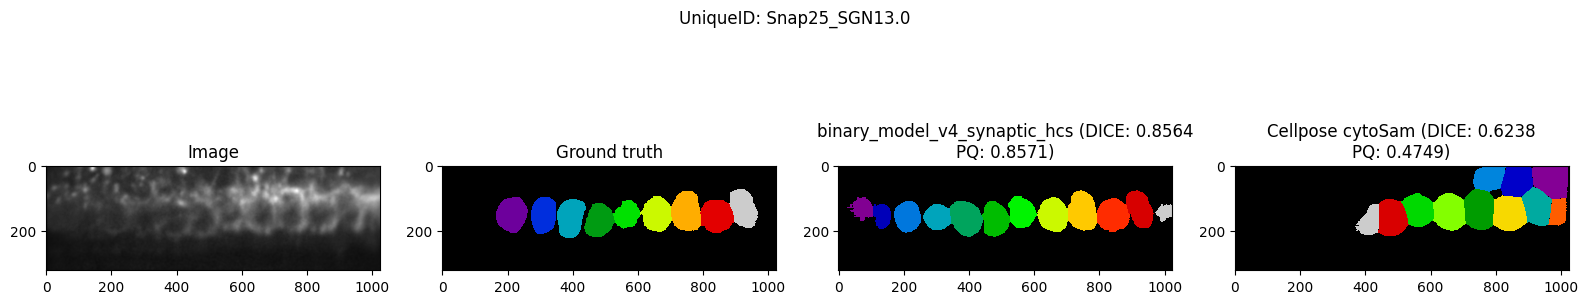

Predicting Cellpose labels for NeuroD_SGN47.0...


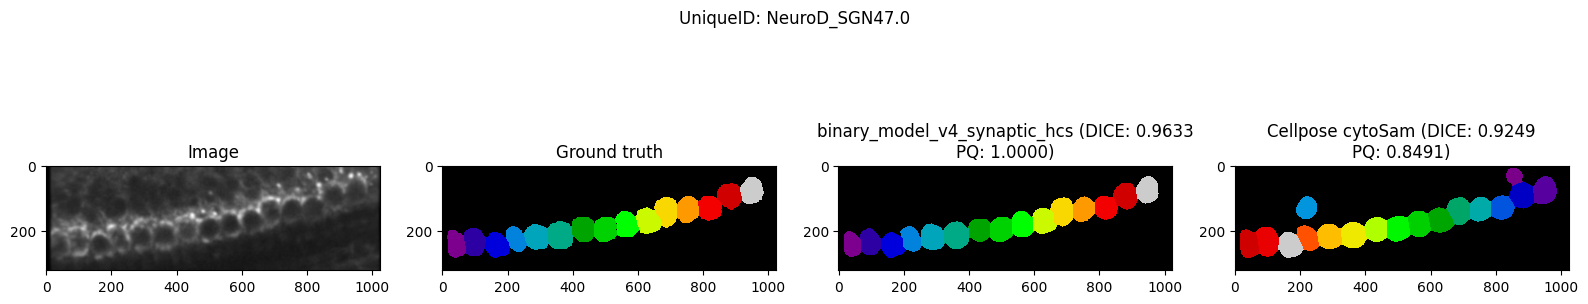

Predicting Cellpose labels for NeuroD_SGN_ex_vivo13.0...


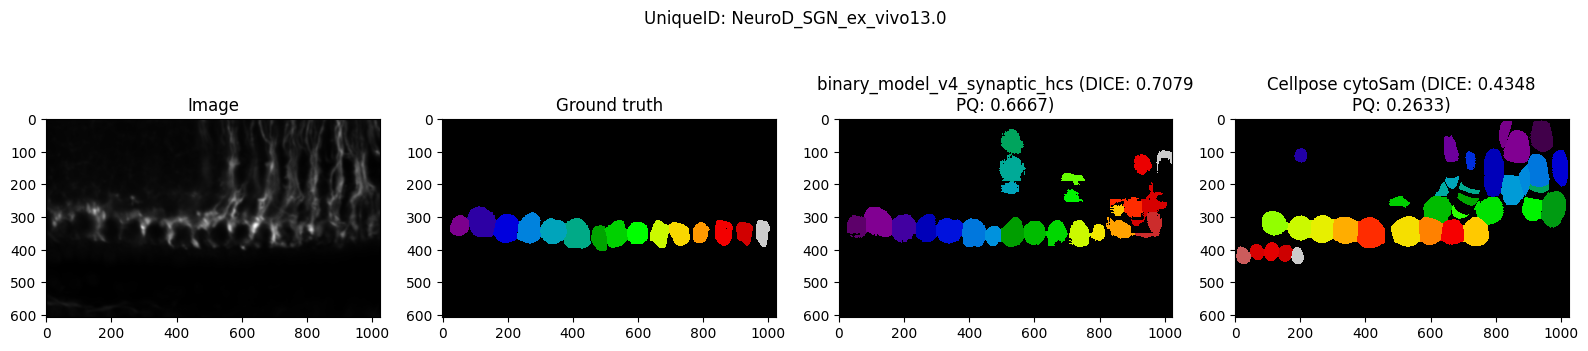

Predicting Cellpose labels for NeuroD_SGN_ACP+isoflurane_na15.0...


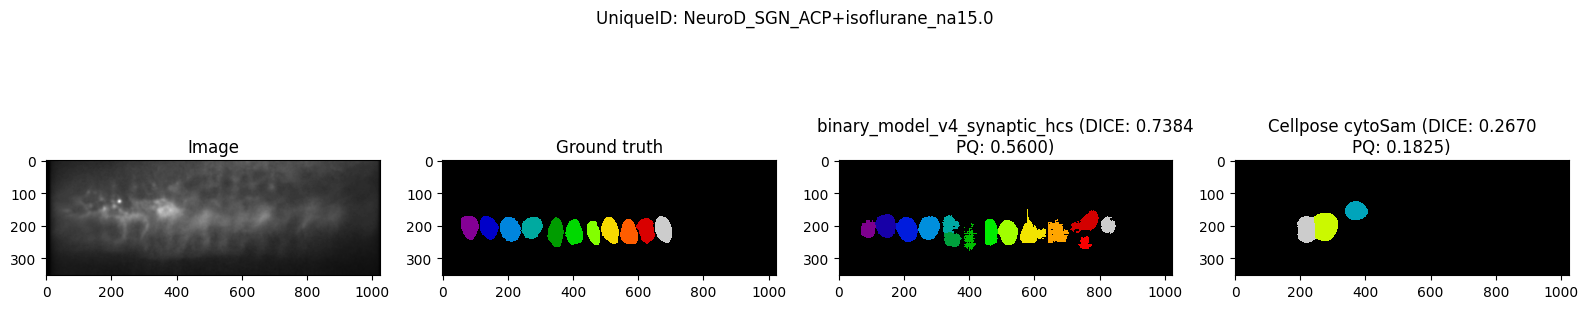

Predicting Cellpose labels for NeuroD_SGN_ACP+isoflurane_na4.0...


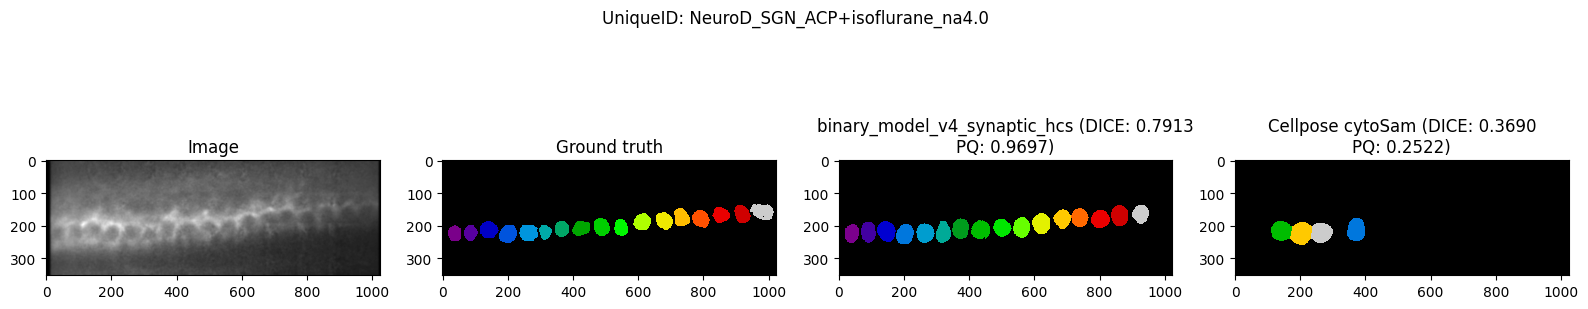

Predicting Cellpose labels for NeuroD_SGN_ex_vivo13.0...


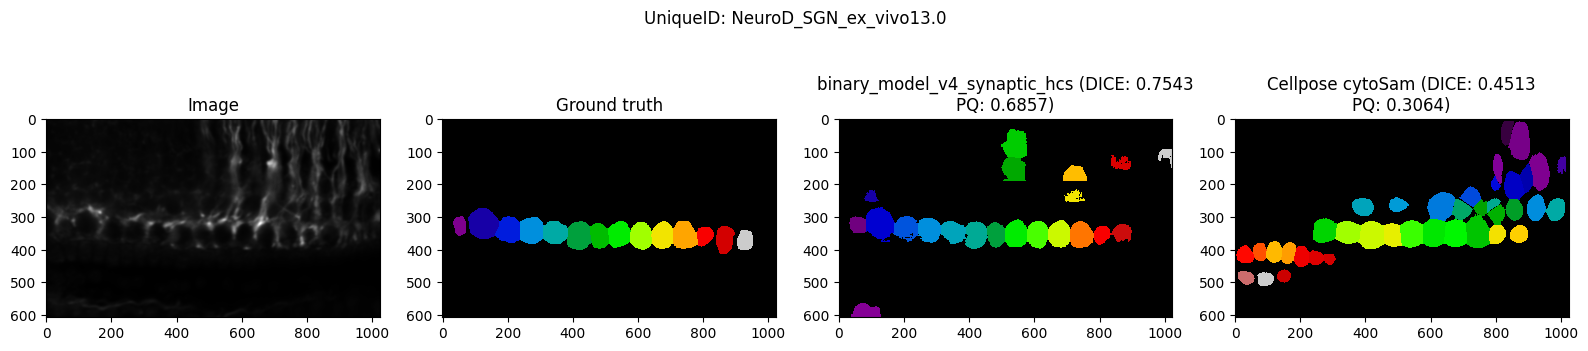

Predicting Cellpose labels for NeuroD_SGN_ACP+isoflurane_na8.0...


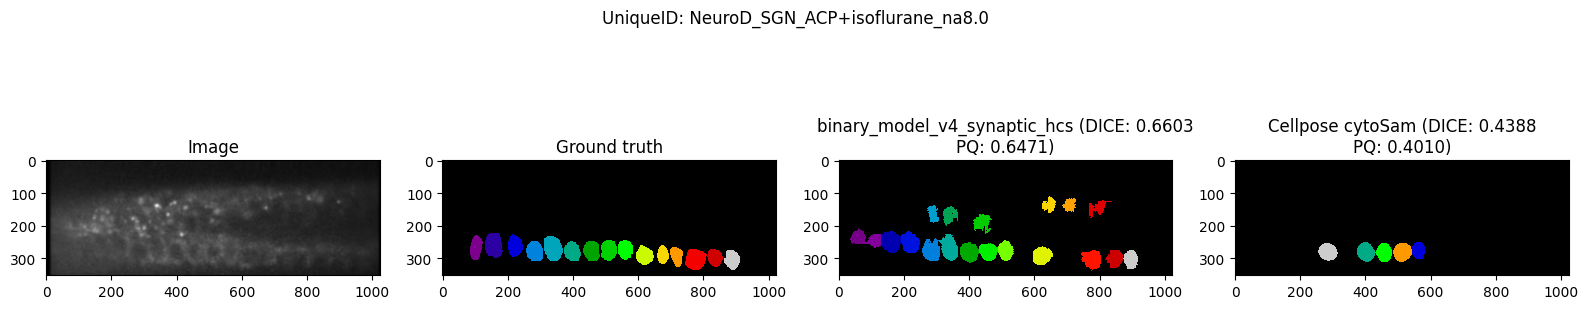

Predicting Cellpose labels for NeuroD_SGN_ex_vivo8.0...


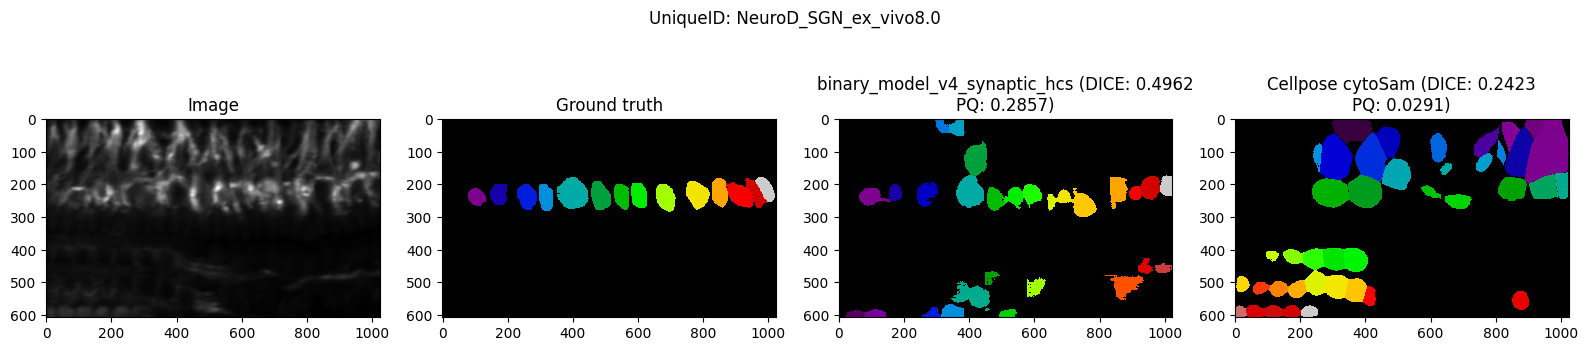

Predicting Cellpose labels for Snap25_SGN13.0...


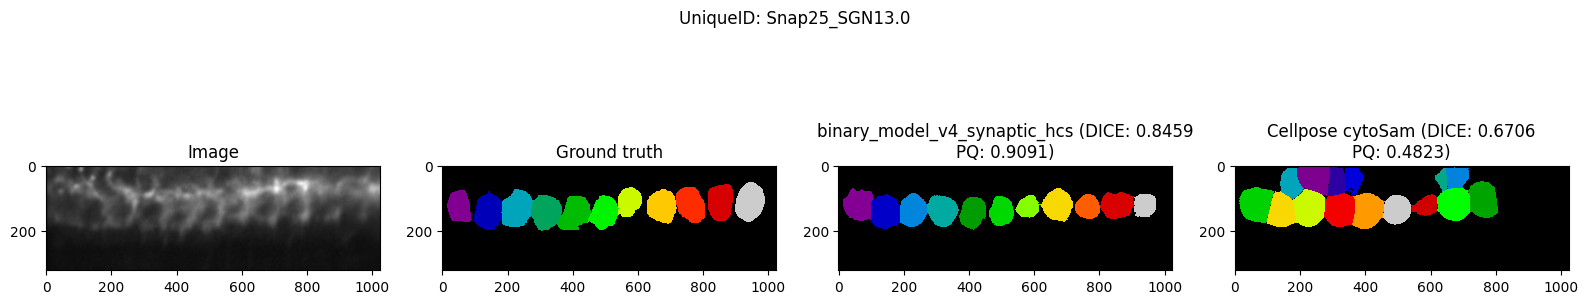

Predicting Cellpose labels for NeuroD_SGN_ACP+isoflurane_na14.0...


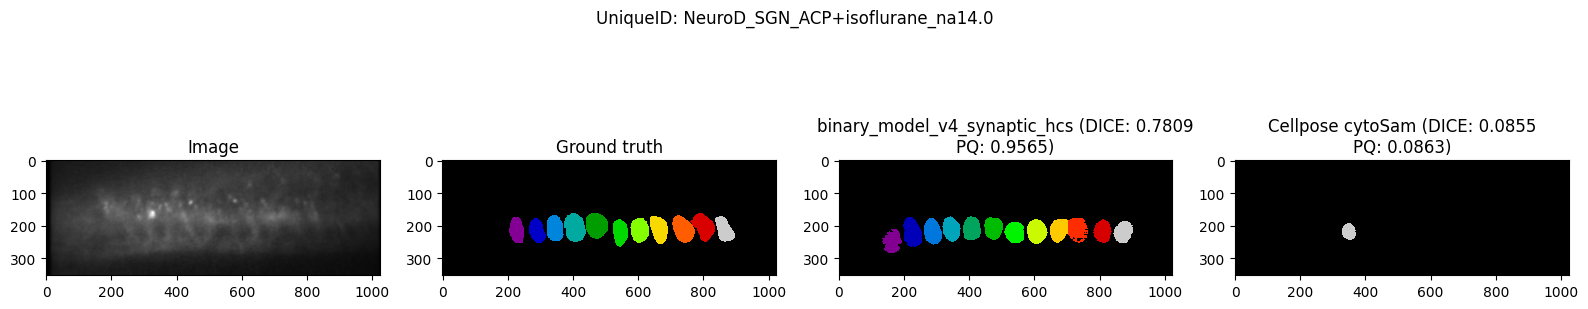

Predicting Cellpose labels for NeuroD_SGN_ACP+isoflurane_na23.0...


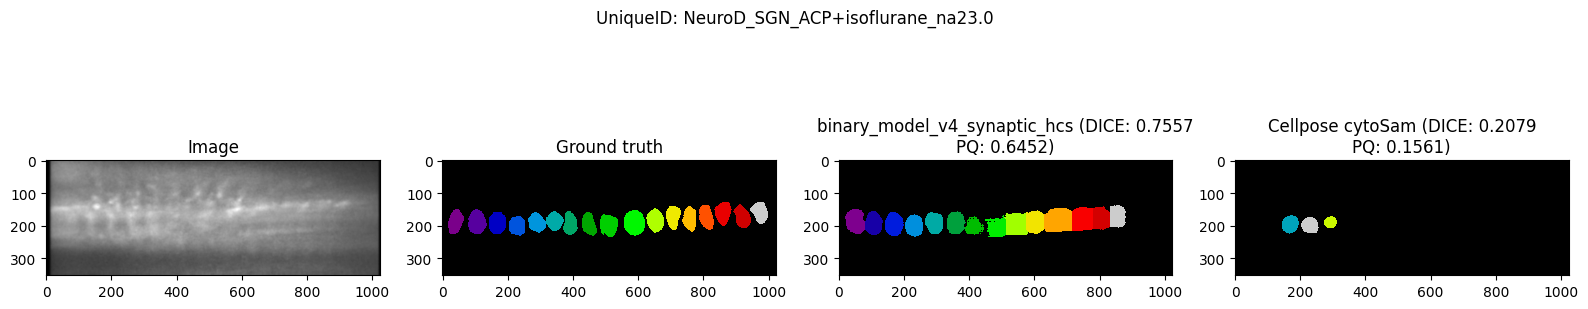

Predicting Cellpose labels for NeuroD_SGN_ex_vivo2.0...


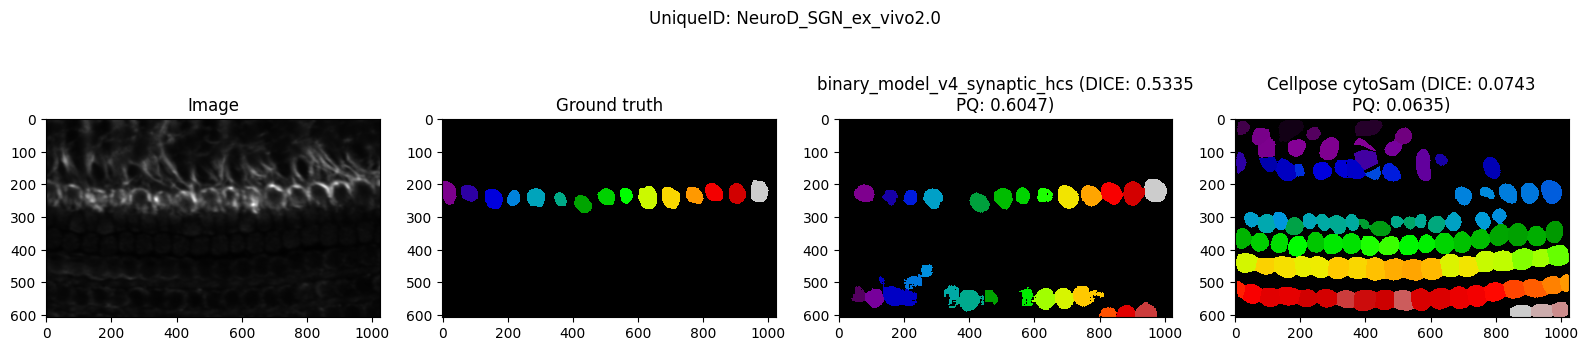

Predicting Cellpose labels for Snap25_SGN8.0...


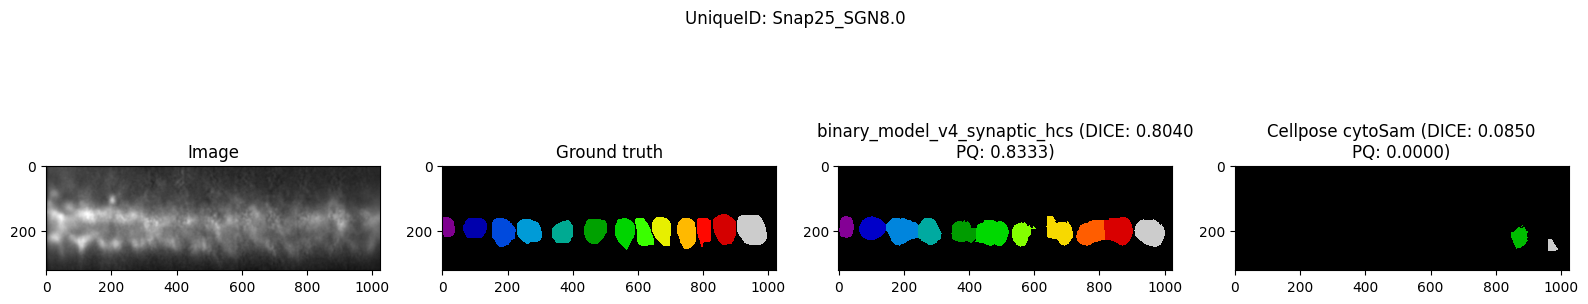

Predicting Cellpose labels for NeuroD_SGN_ACP+isoflurane_na6.0...


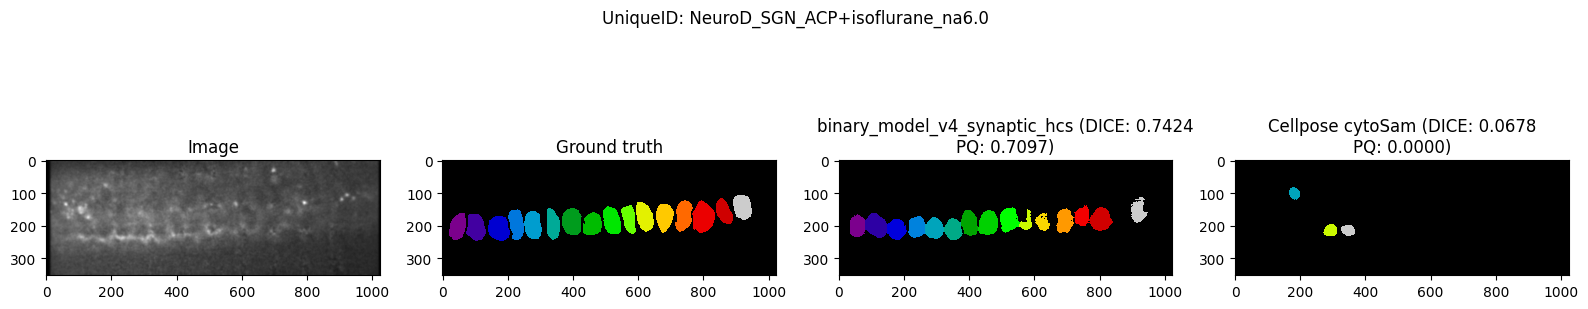

Predicting Cellpose labels for NeuroD_SGN_ex_vivo10.0...


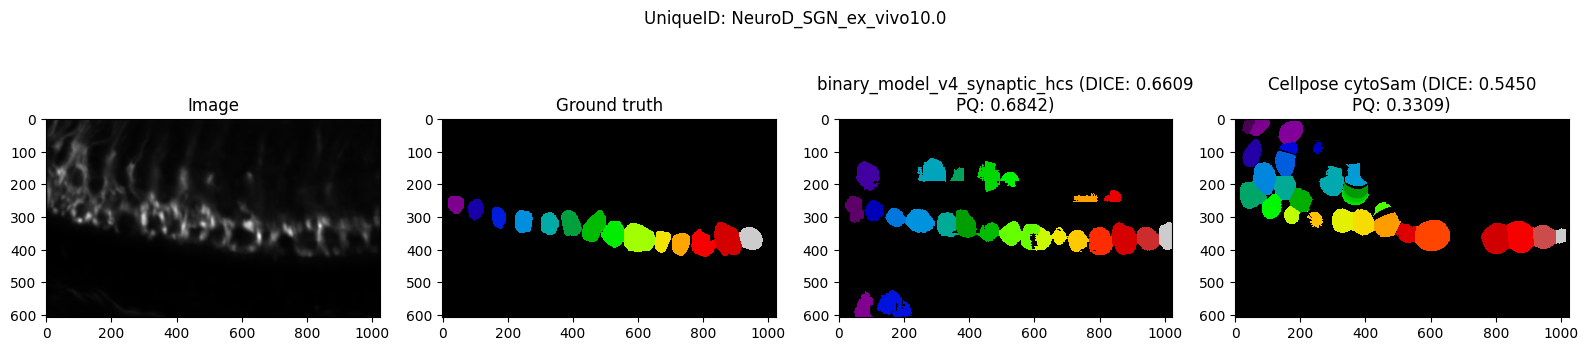

Predicting Cellpose labels for NeuroD_SGN_ACP+isoflurane_na23.0...


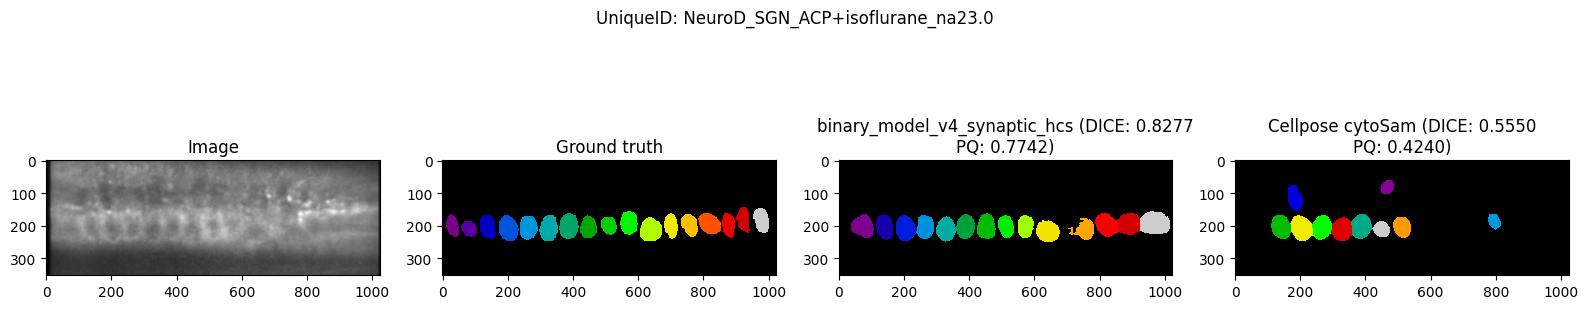

Predicting Cellpose labels for Snap25_SGN13.0...


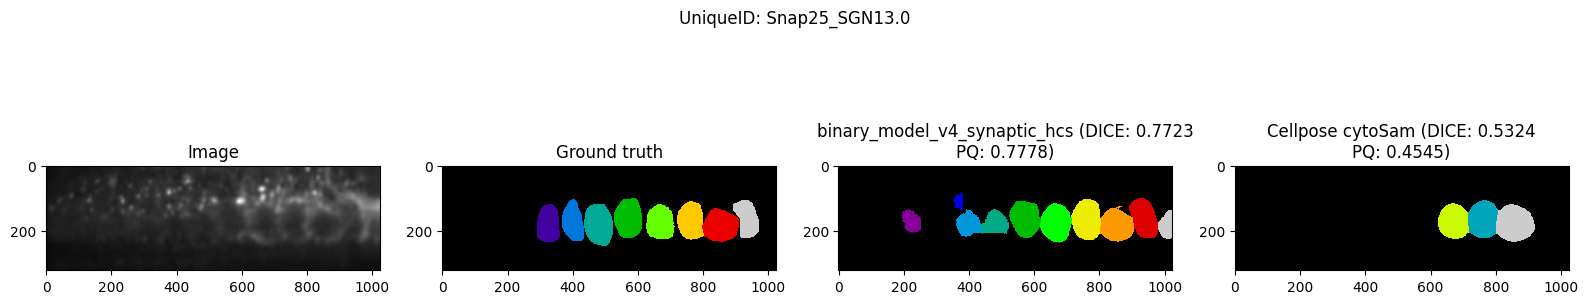

Predicting Cellpose labels for NeuroD_SGN3.0...


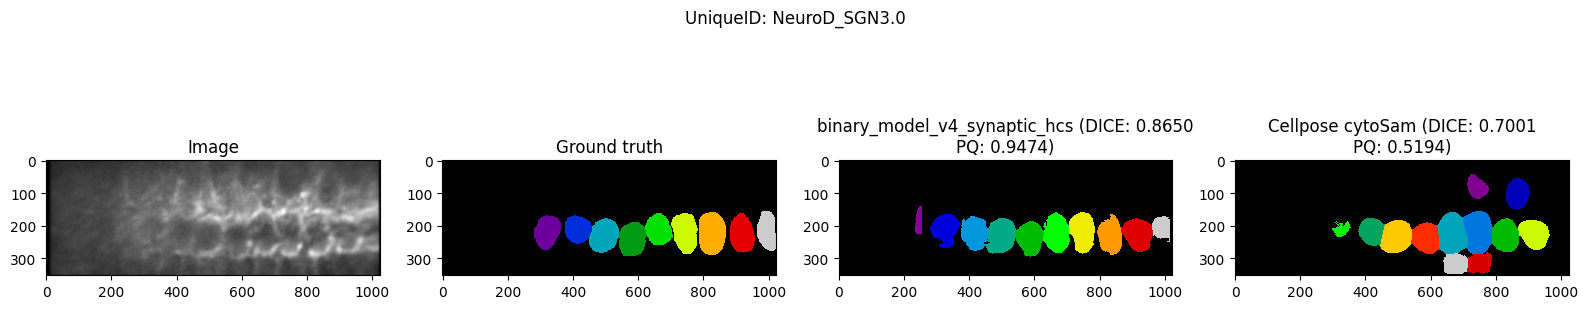

Predicting Cellpose labels for NeuroD_SGN37.0...


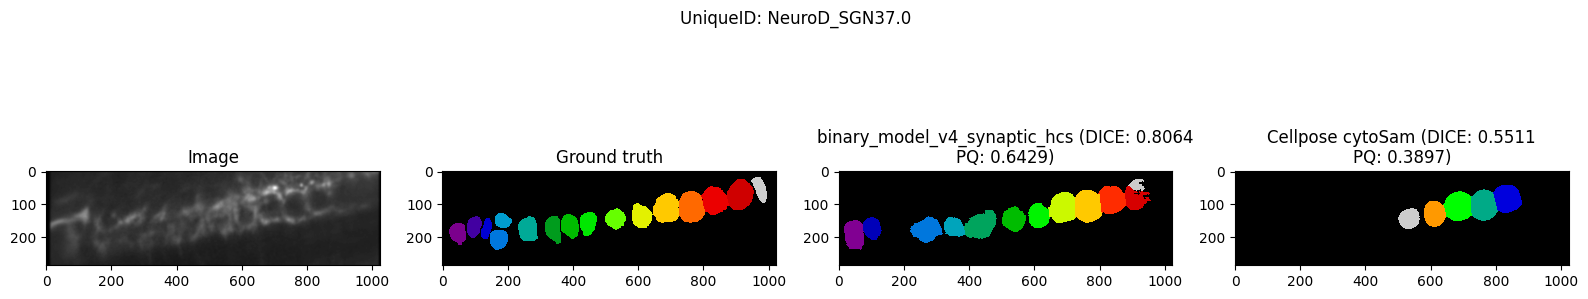

Predicting Cellpose labels for NeuroD_SGN_ex_vivo2.0...


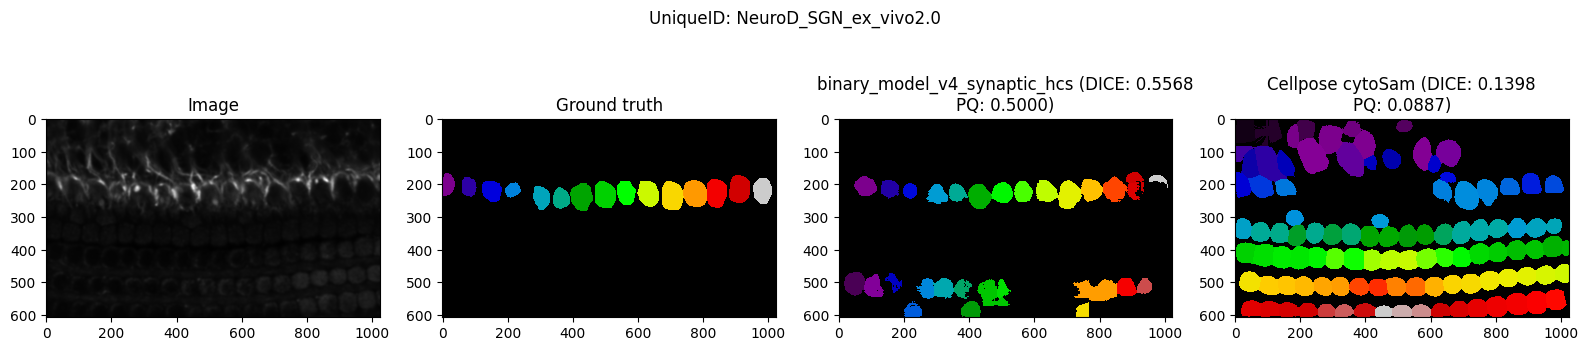

Predicting Cellpose labels for NeuroD_SGN2.0...


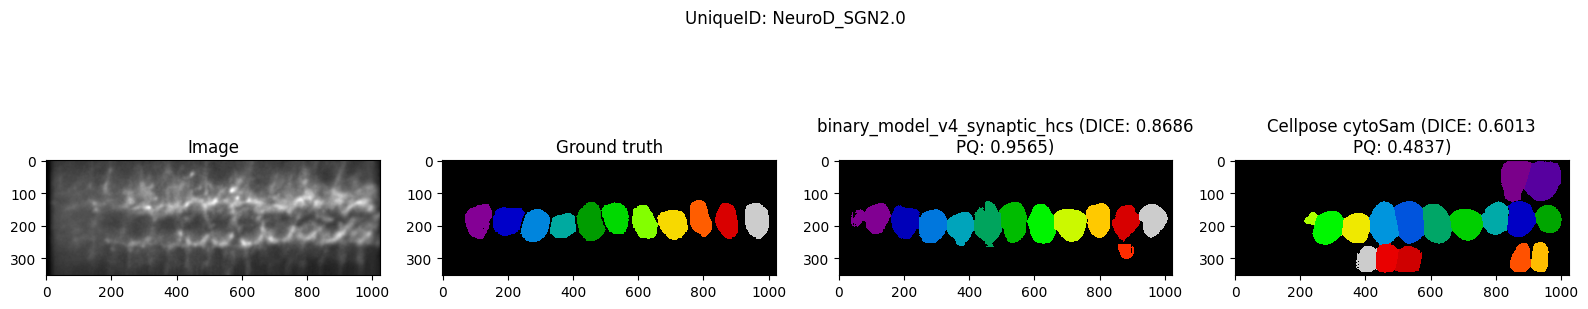

Predicting Cellpose labels for Snap25_SGN17.0...


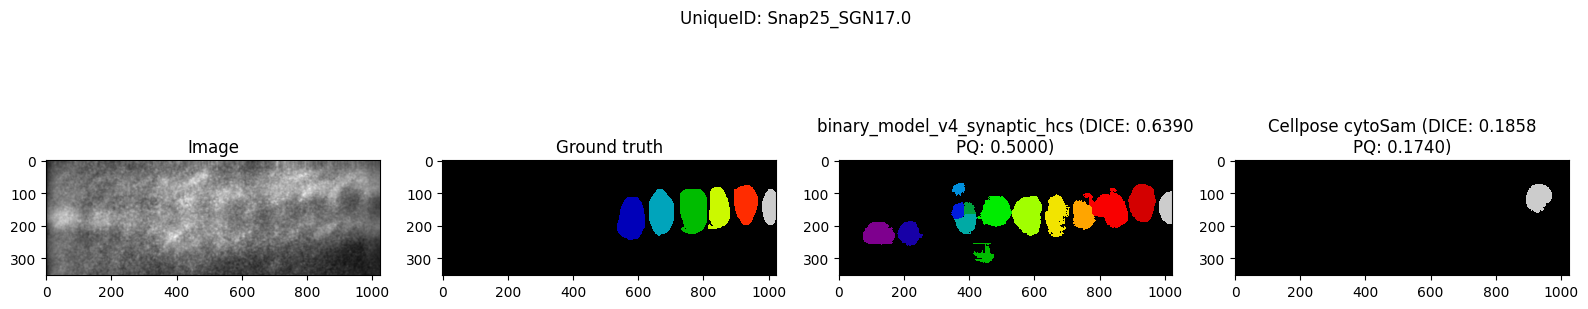

Predicting Cellpose labels for NeuroD_SGN_ACP+isoflurane_na2.0...


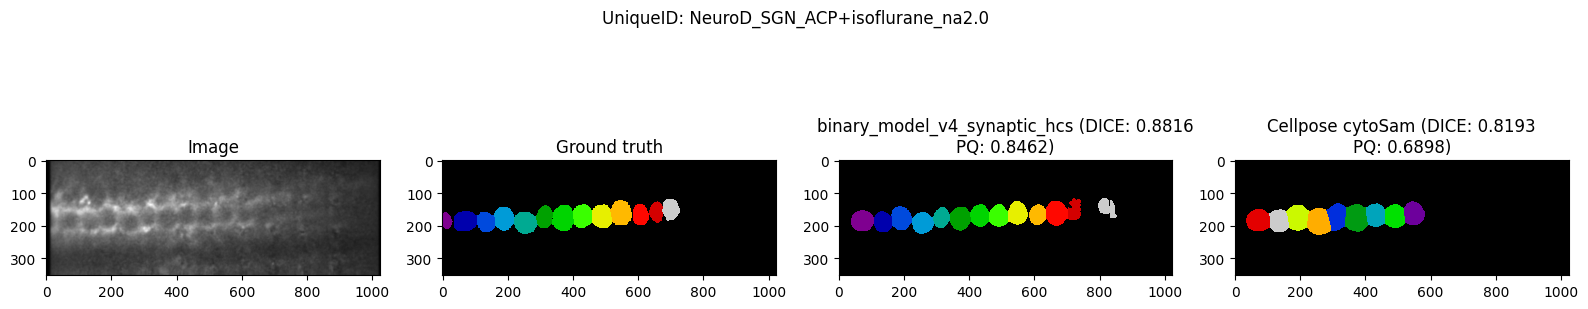

Predicting Cellpose labels for NeuroD_SGN_ACP+isoflurane_na8.0...


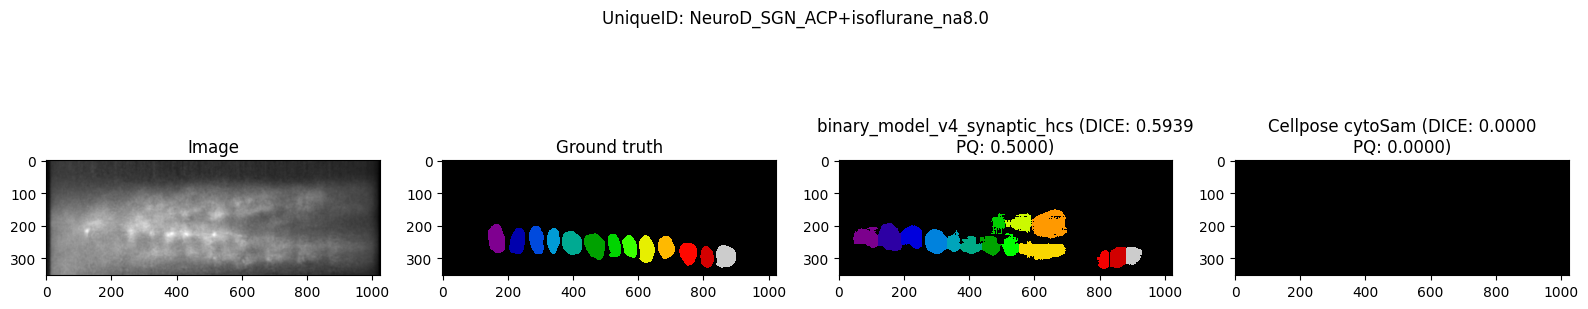

Predicting Cellpose labels for NeuroD_SGN_ex_vivo8.0...


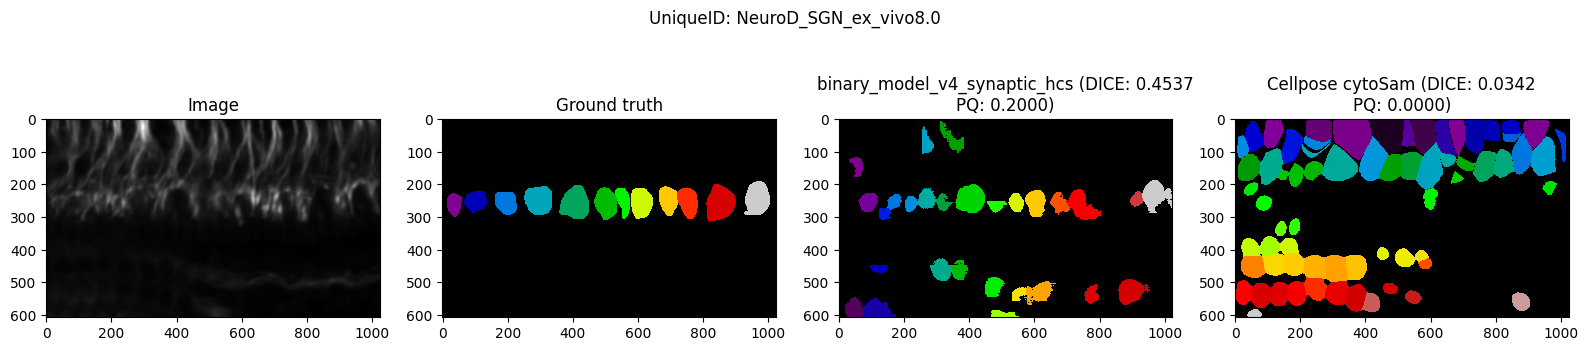

Predicting Cellpose labels for Snap25_SGN3.0...


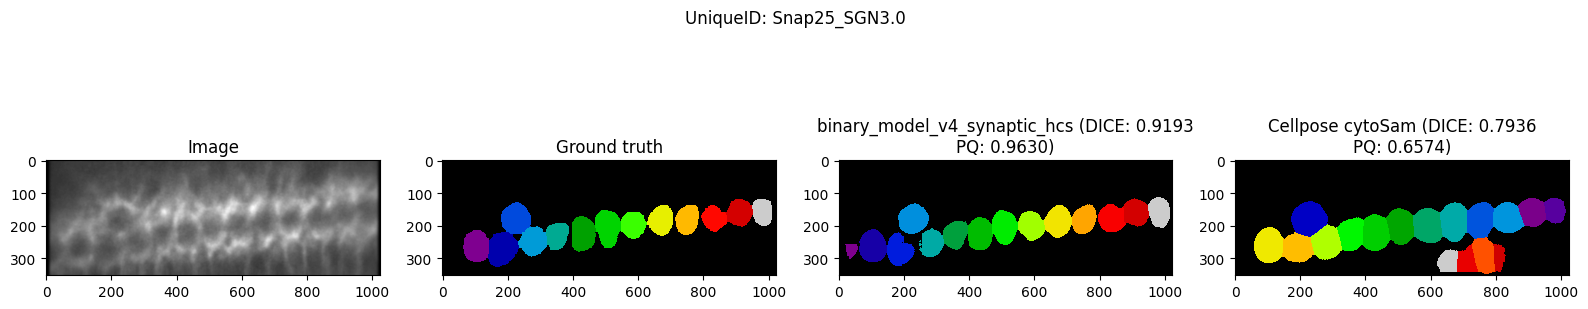

Predicting Cellpose labels for NeuroD_SGN_injectable anaesthetic_na6.0...


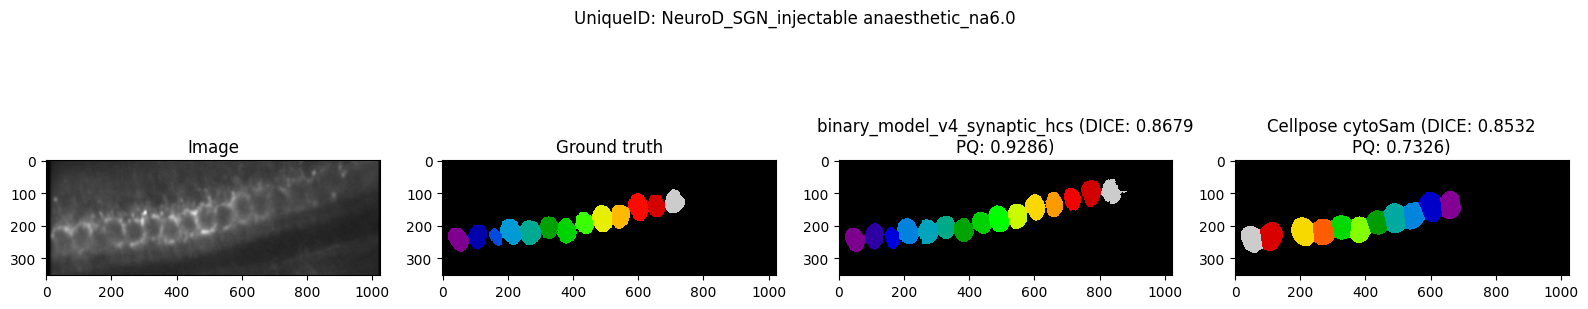

Predicting Cellpose labels for Snap25_SGN4.0...


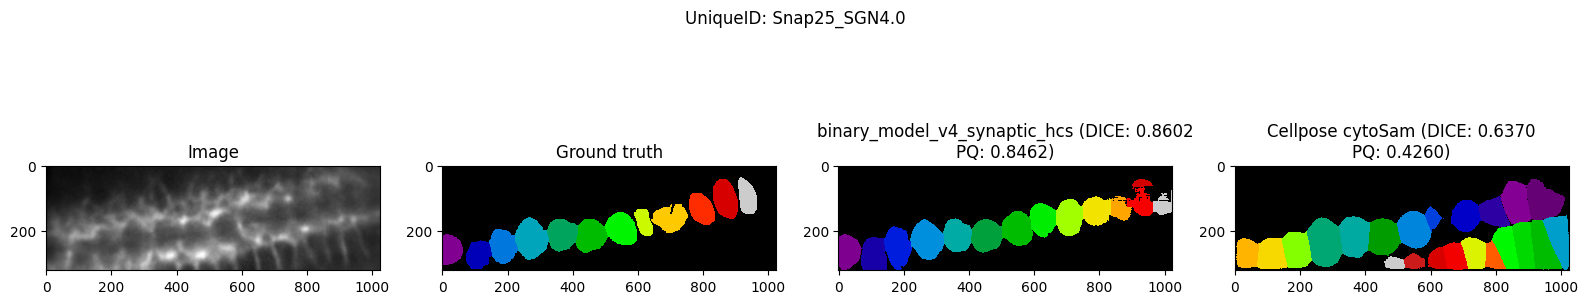

Predicting Cellpose labels for NeuroD_SGN_injectable anaesthetic_na1.0...


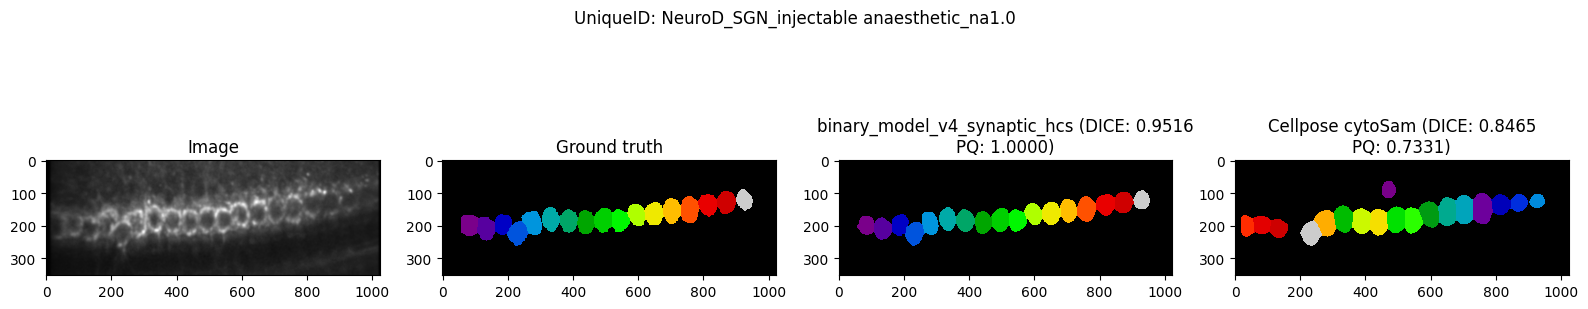

Predicting Cellpose labels for NeuroD_SGN_ex_vivo2.0...


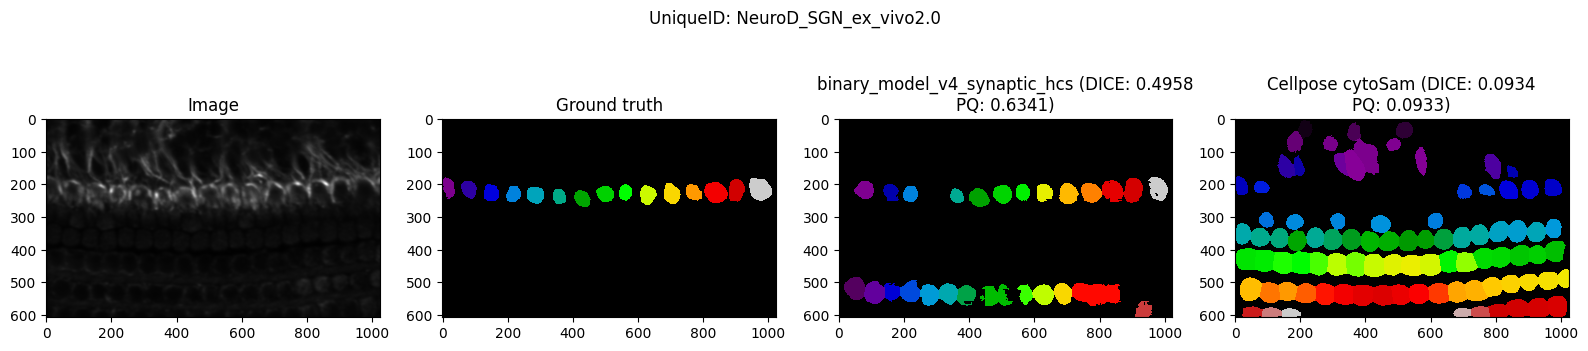

Predicting Cellpose labels for Snap25_SGN3.0...


KeyboardInterrupt: 

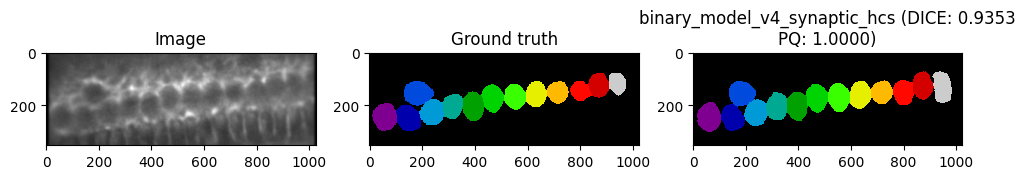

In [23]:
# Imshow the predictions for a few validation images
import matplotlib.pyplot as plt
from src import inference
import tifffile


def first_batch_value(value):
    if isinstance(value, (list, tuple)):
        return value[0]
    return value


def predict_cellpose_labels(cellpose_model, image_array):
    image_array = np.squeeze(np.asarray(image_array))
    eval_kwargs = {
        "diameter": CELLPOSE_DIAMETER,
        "flow_threshold": CELLPOSE_FLOW_THRESHOLD,
        "cellprob_threshold": CELLPOSE_CELLPROB_THRESHOLD,
        "min_size": CELLPOSE_MIN_SIZE,
    }
    if CELLPOSE_MODEL_NAME.lower() == "cyto2":
        eval_kwargs["channels"] = CELLPOSE_CHANNELS
    result = cellpose_model.eval(image_array, **eval_kwargs)
    masks = result[0]
    if isinstance(masks, list):
        masks = masks[0]
    return masks.astype(np.uint32)

from monai.metrics import DiceMetric, compute_panoptic_quality

with torch.no_grad():
    for i, batch in enumerate(val_loader):
        image = batch["image"].to(device)
        label = batch["label"].to(device)
        uniqueid = first_batch_value(batch[data_config["column"]])
        original_image_file = first_batch_value(batch["image_path"])
        original_label_file = first_batch_value(batch["label_path"])
        original_image = tifffile.imread(original_image_file)
        original_label = tifffile.imread(original_label_file)
        gt = label

        ncols = 3 + len(model_runs)
        plt.figure(figsize=(4 * ncols, 4))

        plt.subplot(1, ncols, 1)
        plt.imshow(image[0, 0].cpu(), cmap="gray")
        plt.title("Image")

        plt.subplot(1, ncols, 2)
        #plt.imshow(gt[0, 0].cpu(), cmap="gray")
        plt.imshow(original_label, cmap="nipy_spectral", interpolation="none")
        plt.title("Ground truth")

        for col, run in enumerate(model_runs, start=3):
            run_validation_config = run["config"]["validation"]
            pred = inference.predict_labels(
                run["model"],
                image,
                device,
                roi_size=tuple(run_validation_config["roi_size"]),
                sw_batch_size=run_validation_config["sw_batch_size"],
                prediction_sigmoid=run_validation_config["prediction_sigmoid"],
                prediction_threshold=run_validation_config["prediction_threshold"],
                min_distance=25,
                min_size=1000
            )
            
            plt.subplot(1, ncols, col)
            plt.imshow(pred, cmap="nipy_spectral", interpolation="none")
            #Calculate DICE score
            dice_metric = DiceMetric(include_background=False, reduction="mean") #TODO: use panoptic quality instead
            #convert pred to tensor of shape (1, 1, H, W) to match gt shape
            pred_gray = (pred > 0.5).astype(np.float32)  # Convert to binary mask
            pred_gray_tensor = torch.from_numpy(pred_gray).unsqueeze(0).unsqueeze(0).to(device)
            dice_score = dice_metric(pred_gray_tensor, gt).item()

            pred_tensor = torch.from_numpy(pred).unsqueeze(0).unsqueeze(0).to(device)
            original_label_tensor = torch.from_numpy(original_label).unsqueeze(0).unsqueeze(0).to(device)
            panoptic_quality = compute_panoptic_quality(pred_tensor, original_label_tensor,
                                    metric_name="rq",
                                    remap=True,
                                    match_iou_threshold=0.5,).item()
            plt.title(f"{run['name']} (DICE: {dice_score:.4f}\nPQ: {panoptic_quality:.4f})")
            
        print(f"Predicting Cellpose labels for {uniqueid}...")
        cellpose_labels = predict_cellpose_labels(cellpose_model, original_image)
        plt.subplot(1, ncols, ncols)
        plt.imshow(cellpose_labels, cmap="nipy_spectral", interpolation="none")
        
        dice_metric = DiceMetric(include_background=False, reduction="mean")


        #convert pred to tensor of shape (1, 1, H, W) to match gt shape
        pred_gray = (cellpose_labels > 0.5).astype(np.float32)  # Convert to binary mask
        pred_gray_tensor = torch.from_numpy(pred_gray).unsqueeze(0).unsqueeze(0).to(device)
        dice_score = dice_metric(pred_gray_tensor, gt).item()

        cellpose_tensor = torch.from_numpy(cellpose_labels.astype(np.float32)).unsqueeze(0).unsqueeze(0).to(device)
        panoptic_quality = compute_panoptic_quality(cellpose_tensor, original_label_tensor).item()
        plt.title(f"Cellpose {CELLPOSE_MODEL_NAME} (DICE: {dice_score:.4f}\nPQ: {panoptic_quality:.4f})")

        plt.suptitle(f"UniqueID: {uniqueid}")
        plt.tight_layout()
        plt.show()

        if i >= 30:
            break


In [ ]:
gt.shape

torch.Size([1, 1, 352, 1024])